# Tourism Data Preprocessing

This notebook describes the preprocessing steps applied to the tourism dataset obtained from the Swedish Agency for Economic and Regional Growth (Tillväxtverket).

The dataset contains monthly guest-night statistics for registered accommodation establishments in Swedish municipalities between January 2008 and December 2025.

The following features are included:

- **Municipality code** – Four-digit identifier for each Swedish municipality.
- **Municipality** – Name of the municipality.
- **Accommodation type** – Category of registered accommodation, such as hotel, camping or hostel.
- **Month** – Month and year of the observation.
- **Guest nights** – Number of nights spent by guests at registered accommodation establishments.

The original Excel dataset contains metadata rows and stores monthly observations in separate columns. Furthermore, the dataset contains missing values and confidentiality-protected observations.

The purpose of preprocessing is to transform the dataset into a consistent structure suitable for analysis and integration with the Airbnb and housing market datasets used in the SABA project.

The following sections describe the preprocessing steps applied to the dataset.

In [12]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


### Define the dataset location

In [13]:
FILE_PATH = (
    Path.cwd()
    / "tourism_guest_nights_by_accommodation_type.xlsx"
)

OUTPUT_PATH = Path.cwd() / "processed_tourism_data.csv"

print("Input file:", FILE_PATH)
print("File exists:", FILE_PATH.exists())


Input file: c:\Users\kimwo\software engineering\year 5\LP1\4DT911 - Project\4dt911-vis-project-research\notebooks\data_preprocessing\tourism_guest_nights_by_accommodation_type.xlsx
File exists: True


### Load the dataset

In [14]:

df = pd.read_excel(
    FILE_PATH,
    header=2,
    dtype={"Kommun Kod": "string"}
)

df.head(10)


c:\Users\kimwo\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Antal gästnätter,Kommun Kod,Kommun,Anläggningstyp,2008-01,2008-02,2008-03,2008-04,2008-05,2008-06,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,Nivå: Kommun,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0117,Österåker,Hotell,NaN,NaN,NaN,NaN,4440.0,4341.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,0117,Österåker,Sekretesskyddad,3008.0,2918.0,2932.0,4705.0,3138.0,5319.0,...,NaN,2893.0,5810.0,4515.0,6757.0,9063.0,6506.0,NaN,NaN,NaN
3,NaN,0120,Värmdö,Hotell,NaN,NaN,NaN,NaN,11695.0,10089.0,...,NaN,7132.0,12920.0,14107.0,20414.0,21589.0,15563.0,12660.0,NaN,NaN
4,NaN,0120,Värmdö,Camping,NaN,NaN,NaN,NaN,NaN,5725.0,...,NaN,NaN,7523.0,7414.0,15971.0,13833.0,4341.0,NaN,NaN,NaN
5,NaN,0120,Värmdö,Vandrarhem,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,0120,Värmdö,Sekretesskyddad,5010.0,5974.0,5191.0,10049.0,6116.0,3679.0,...,7677.0,6237.0,1592.0,3050.0,7345.0,6782.0,2279.0,5747.0,11508.0,11109.0
7,NaN,0123,Järfälla,Sekretesskyddad,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,0125,Ekerö,Hotell,NaN,NaN,NaN,NaN,NaN,NaN,...,6177.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8805.0,6669.0
9,NaN,0125,Ekerö,Sekretesskyddad,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,4675.0,8581.0,8377.0,7561.0,8191.0,10558.0,10251.0,NaN,NaN


In [15]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nFirst observations:")
display(df.head())


Dataset shape: (590, 220)

Column names:
['Antal gästnätter', 'Kommun Kod', 'Kommun', 'Anläggningstyp', '2008-01', '2008-02', '2008-03', '2008-04', '2008-05', '2008-06', '2008-07', '2008-08', '2008-09', '2008-10', '2008-11', '2008-12', '2009-01', '2009-02', '2009-03', '2009-04', '2009-05', '2009-06', '2009-07', '2009-08', '2009-09', '2009-10', '2009-11', '2009-12', '2010-01', '2010-02', '2010-03', '2010-04', '2010-05', '2010-06', '2010-07', '2010-08', '2010-09', '2010-10', '2010-11', '2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05', '2011-06', '2011-07', '2011-08', '2011-09', '2011-10', '2011-11', '2011-12', '2012-01', '2012-02', '2012-03', '2012-04', '2012-05', '2012-06', '2012-07', '2012-08', '2012-09', '2012-10', '2012-11', '2012-12', '2013-01', '2013-02', '2013-03', '2013-04', '2013-05', '2013-06', '2013-07', '2013-08', '2013-09', '2013-10', '2013-11', '2013-12', '2014-01', '2014-02', '2014-03', '2014-04', '2014-05', '2014-06', '2014-07', '2014-08', '2014-09', '2014

,Antal gästnätter,Kommun Kod,Kommun,Anläggningstyp,2008-01,2008-02,2008-03,2008-04,2008-05,2008-06,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,Nivå: Kommun,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0117,Österåker,Hotell,NaN,NaN,NaN,NaN,4440.0,4341.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,0117,Österåker,Sekretesskyddad,3008.0,2918.0,2932.0,4705.0,3138.0,5319.0,...,NaN,2893.0,5810.0,4515.0,6757.0,9063.0,6506.0,NaN,NaN,NaN
3,NaN,0120,Värmdö,Hotell,NaN,NaN,NaN,NaN,11695.0,10089.0,...,NaN,7132.0,12920.0,14107.0,20414.0,21589.0,15563.0,12660.0,NaN,NaN
4,NaN,0120,Värmdö,Camping,NaN,NaN,NaN,NaN,NaN,5725.0,...,NaN,NaN,7523.0,7414.0,15971.0,13833.0,4341.0,NaN,NaN,NaN


## Initial Data Cleaning

The original Excel file contains metadata and descriptive columns that are not necessary for the analysis.

The following operations are performed:

- Remove rows that do not represent valid municipalities.
- Remove the redundant metadata column.
- Identify monthly observation columns.
- Preserve municipality codes as four-character strings.
- Filter observations to municipalities in Stockholm County.

Stockholm County municipalities can be identified using municipality codes beginning with `01`.

In [16]:

# Identify monthly columns (YYYY-MM)
month_columns = [
    col for col in df.columns
    if isinstance(col, str)
    and pd.notna(
        pd.to_datetime(
            col,
            format="%Y-%m",
            errors="coerce"
        )
    )
]

# Keep relevant columns
columns_to_keep = [
    "Kommun Kod",
    "Kommun",
    "Anläggningstyp"
] + month_columns

df = df[columns_to_keep].copy()

# Standardize municipality codes
df["Kommun Kod"] = df["Kommun Kod"].str.strip().str.zfill(4)

# Remove rows without a valid 4-digit code
df = df[
    df["Kommun Kod"].str.fullmatch(
        r"\d{4}", na=False
    )
].copy()

print("Remaining rows:", len(df))
print("Monthly columns:", len(month_columns))
print("First month:", month_columns[0])
print("Last month:", month_columns[-1])


Remaining rows: 587
Monthly columns: 216
First month: 2008-01
Last month: 2025-12


### Filter stockholm county

In [17]:

# Filter using municipality codes
df = df[
    df["Kommun Kod"].str.startswith("01", na=False)
].copy()

print("Rows after filtering:", len(df))

print(
    "Number of municipalities:",
    df["Kommun Kod"].nunique()
)

print("\nMunicipalities:")
display(
    df[["Kommun Kod", "Kommun"]]
    .drop_duplicates()
    .sort_values("Kommun")
)


Rows after filtering: 39
Number of municipalities: 19

Municipalities:


,Kommun Kod,Kommun
12,0127,Botkyrka
8,0125,Ekerö
13,0136,Haninge
10,0126,Huddinge
7,0123,Järfälla
30,0186,Lidingö
26,0182,Nacka
33,0188,Norrtälje
38,0192,Nynäshamn
36,0191,Sigtuna


In [18]:

print("Accommodation types:")
print(df["Anläggningstyp"].value_counts(dropna=False))

print("\nMissing values in identification columns:")
print(
    df[
        ["Kommun Kod", "Kommun", "Anläggningstyp"]
    ].isna().sum()
)

print("\nDuplicate municipality-category pairs:")
print(
    df.duplicated(
        subset=["Kommun Kod", "Anläggningstyp"]
    ).sum()
)


Accommodation types:
Anläggningstyp
Sekretesskyddad    19
Hotell             14
Camping             3
Vandrarhem          3
Name: count, dtype: int64

Missing values in identification columns:
Kommun Kod        0
Kommun            0
Anläggningstyp    0
dtype: int64

Duplicate municipality-category pairs:
0


## Restructuring the Dataset

The original dataset uses a wide format, where each month is represented by a separate column.

To simplify data analysis, the dataset is transformed into long format, where each row represents one municipality, accommodation type and month.

This transformation allows observations to be grouped, filtered and compared across both time and geographic locations.

The transformation is performed using the pandas `melt()` function.

In [19]:

df = df.melt(
    id_vars=[
        "Kommun Kod",
        "Kommun",
        "Anläggningstyp"
    ],
    value_vars=month_columns,
    var_name="date",
    value_name="guest_nights"
)

print("New dataset shape:", df.shape)

df.head(10)


New dataset shape: (8424, 5)


,Kommun Kod,Kommun,Anläggningstyp,date,guest_nights
0,0117,Österåker,Hotell,2008-01,NaN
1,0117,Österåker,Sekretesskyddad,2008-01,3008.0
2,0120,Värmdö,Hotell,2008-01,NaN
3,0120,Värmdö,Camping,2008-01,NaN
4,0120,Värmdö,Vandrarhem,2008-01,NaN
5,0120,Värmdö,Sekretesskyddad,2008-01,5010.0
6,0123,Järfälla,Sekretesskyddad,2008-01,NaN
7,0125,Ekerö,Hotell,2008-01,NaN
8,0125,Ekerö,Sekretesskyddad,2008-01,NaN
9,0126,Huddinge,Hotell,2008-01,NaN


In [20]:

# Rename columns to English
df = df.rename(columns={
    "Kommun Kod": "municipality_code",
    "Kommun": "municipality",
    "Anläggningstyp": "accommodation_type"
})

# Translate accommodation types
accommodation_mapping = {
    "Hotell": "Hotel",
    "Camping": "Camping",
    "Vandrarhem": "Hostel",
    "Stugbyar": "Holiday village",
    "Sekretesskyddad": "Confidential"
}

# Preserve original values for traceability
df["accommodation_type_original"] = df["accommodation_type"]

df["accommodation_type"] = df[
    "accommodation_type"
].replace(accommodation_mapping)

print("Accommodation types:")
print(df["accommodation_type"].unique())

df.head()


Accommodation types:
['Hotel' 'Confidential' 'Camping' 'Hostel']


,municipality_code,municipality,accommodation_type,date,guest_nights,accommodation_type_original
0,0117,Österåker,Hotel,2008-01,NaN,Hotell
1,0117,Österåker,Confidential,2008-01,3008.0,Sekretesskyddad
2,0120,Värmdö,Hotel,2008-01,NaN,Hotell
3,0120,Värmdö,Camping,2008-01,NaN,Camping
4,0120,Värmdö,Hostel,2008-01,NaN,Vandrarhem


In [21]:

# Convert dates to datetime
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m",
    errors="raise"
)

# Identify unexpected non-numeric observations
numeric_guest_nights = pd.to_numeric(
    df["guest_nights"],
    errors="coerce"
)

invalid_numeric = (
    df["guest_nights"].notna()
    & numeric_guest_nights.isna()
)

print(
    "Unexpected non-numeric guest-night values:",
    invalid_numeric.sum()
)

if invalid_numeric.any():
    display(df.loc[invalid_numeric])

# Convert guest nights to numeric
df["guest_nights"] = numeric_guest_nights

print("\nUpdated data types:")
print(df.dtypes)


Unexpected non-numeric guest-night values: 0

Updated data types:
municipality_code              string[python]
municipality                           object
accommodation_type                     object
date                           datetime64[ns]
guest_nights                          float64
accommodation_type_original            object
dtype: object


## Missing Value Analysis

The dataset contains missing monthly observations for some municipalities and accommodation types.

Missing observations may represent unavailable, unreported or confidentiality-affected data. Their exact meaning cannot be determined solely from the spreadsheet.

Therefore, missing guest-night values are preserved as `NaN` rather than being replaced with zero.

Replacing missing values with zero could incorrectly suggest that no visitors stayed in an accommodation category during a particular month.

The number and distribution of missing observations are investigated before proceeding with further analysis.

In [22]:

# Missing values per column
missing_values = df.isna().sum()

print("Missing values:")
print(missing_values)

# Total missing guest nights
missing_count = df["guest_nights"].isna().sum()

missing_percentage = (
    missing_count / len(df) * 100
)

print(f"\nMissing guest-night values: {missing_count}")
print(f"Missing percentage: {missing_percentage:.2f}%")

# Missing values by accommodation type
missing_by_type = (
    df.groupby("accommodation_type")["guest_nights"]
    .agg(
        total="size",
        available="count"
    )
)

missing_by_type["missing"] = (
    missing_by_type["total"]
    - missing_by_type["available"]
)

missing_by_type["missing_percentage"] = (
    missing_by_type["missing"]
    / missing_by_type["total"]
    * 100
)

display(missing_by_type)


Missing values:
municipality_code                 0
municipality                      0
accommodation_type                0
date                              0
guest_nights                   3610
accommodation_type_original       0
dtype: int64

Missing guest-night values: 3610
Missing percentage: 42.85%


,total,available,missing,missing_percentage
accommodation_type,,,,
Camping,648,326,322,49.691358
Confidential,4104,2875,1229,29.946394
Hostel,648,113,535,82.561728
Hotel,3024,1500,1524,50.396825


### Check for duplicates and invalid values

In [23]:

# Identify duplicate observations
key_columns = [
    "municipality_code",
    "accommodation_type",
    "date"
]

duplicates = df.duplicated(
    subset=key_columns,
    keep=False
)

print("Duplicate observations:", duplicates.sum())

if duplicates.any():
    display(
        df.loc[duplicates]
        .sort_values(key_columns)
    )

# Check for negative guest nights
negative_values = df["guest_nights"] < 0

print(
    "Negative guest-night observations:",
    negative_values.sum()
)

# Check the date range
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())

# Validate important assumptions
assert not duplicates.any(), "Duplicate keys detected"
assert not negative_values.any(), "Negative guest nights detected"


Duplicate observations: 0
Negative guest-night observations: 0
Earliest date: 2008-01-01 00:00:00
Latest date: 2025-12-01 00:00:00


In [24]:

# Extract year and month
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Define seasons using a consistent month mapping
season_mapping = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

df["season"] = df["month"].map(season_mapping)

df[
    [
        "municipality",
        "accommodation_type",
        "date",
        "year",
        "month",
        "season",
        "guest_nights"
    ]
].head()


,municipality,accommodation_type,date,year,month,season,guest_nights
0,Österåker,Hotel,2008-01-01,2008,1,Winter,NaN
1,Österåker,Confidential,2008-01-01,2008,1,Winter,3008.0
2,Värmdö,Hotel,2008-01-01,2008,1,Winter,NaN
3,Värmdö,Camping,2008-01-01,2008,1,Winter,NaN
4,Värmdö,Hostel,2008-01-01,2008,1,Winter,NaN


### Inspect completeness across municipalities

In [25]:

# Calculate availability of guest-night observations
municipality_completeness = (
    df.groupby("municipality")["guest_nights"]
    .agg(
        total_observations="size",
        available_observations="count"
    )
)

municipality_completeness["completeness_pct"] = (
    municipality_completeness["available_observations"]
    / municipality_completeness["total_observations"]
    * 100
)

display(
    municipality_completeness.sort_values(
        "completeness_pct", ascending=False
    )
)


,total_observations,available_observations,completeness_pct
municipality,,,
Vaxholm,216,216,100.000000
Sollentuna,216,212,98.148148
Norrtälje,648,632,97.530864
Södertälje,432,383,88.657407
Täby,216,151,69.907407
Nynäshamn,432,282,65.277778
Stockholm,864,528,61.111111
Österåker,432,241,55.787037
Haninge,648,347,53.549383


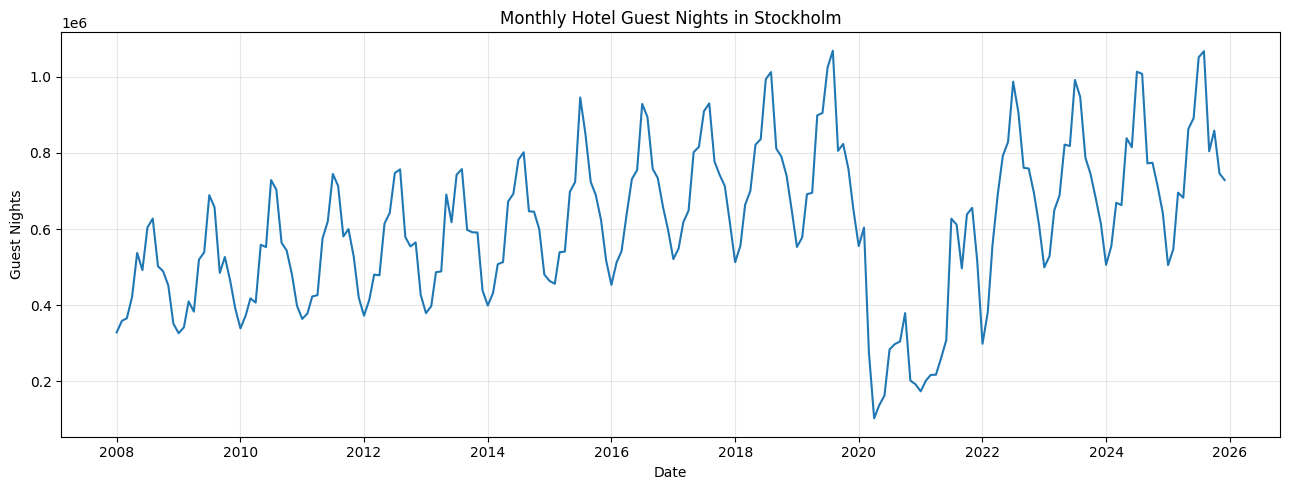

In [26]:

# Select hotel observations for Stockholm municipality
stockholm_hotels = df[
    (df["municipality"] == "Stockholm")
    & (df["accommodation_type"] == "Hotel")
].sort_values("date")

plt.figure(figsize=(13, 5))

plt.plot(
    stockholm_hotels["date"],
    stockholm_hotels["guest_nights"]
)

plt.title("Monthly Hotel Guest Nights in Stockholm")
plt.xlabel("Date")
plt.ylabel("Guest Nights")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Final Dataset

The tourism dataset has been preprocessed through the following operations:

- Removed unnecessary metadata and invalid rows.
- Filtered the dataset to Stockholm County municipalities.
- Reshaped the dataset from wide to long format.
- Renamed variables and accommodation categories to English.
- Converted dates and guest-night values into appropriate data types.
- Investigated missing values and preserved unavailable observations.
- Checked for duplicate observations and invalid numerical values.
- Created additional temporal features for future analysis.

The processed dataset is exported as `processed_tourism_data.csv`.

The resulting dataset can be used for tourism-related visualizations and subsequent integration with the housing market and Airbnb datasets.

**Limitations:** The dataset contains only 19 of Stockholm County's 26 municipalities. Missing observations are preserved, and the confidentiality-protected accommodation category remains identified separately. These limitations must be considered when calculating aggregate tourism statistics.

In [27]:

# Arrange columns in a consistent order
column_order = [
    "municipality_code",
    "municipality",
    "accommodation_type",
    "accommodation_type_original",
    "date",
    "year",
    "month",
    "season",
    "guest_nights"
]

df = df[column_order]

# Sort observations
df = df.sort_values(
    [
        "municipality_code",
        "accommodation_type",
        "date"
    ]
).reset_index(drop=True)

# Export as CSV
df.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("Processed dataset saved to:", OUTPUT_PATH)
print("Final shape:", df.shape)

df.head(10)


Processed dataset saved to: c:\Users\kimwo\software engineering\year 5\LP1\4DT911 - Project\4dt911-vis-project-research\notebooks\data_preprocessing\processed_tourism_data.csv
Final shape: (8424, 9)


,municipality_code,municipality,accommodation_type,accommodation_type_original,date,year,month,season,guest_nights
0,0117,Österåker,Confidential,Sekretesskyddad,2008-01-01,2008,1,Winter,3008.0
1,0117,Österåker,Confidential,Sekretesskyddad,2008-02-01,2008,2,Winter,2918.0
2,0117,Österåker,Confidential,Sekretesskyddad,2008-03-01,2008,3,Spring,2932.0
3,0117,Österåker,Confidential,Sekretesskyddad,2008-04-01,2008,4,Spring,4705.0
4,0117,Österåker,Confidential,Sekretesskyddad,2008-05-01,2008,5,Spring,3138.0
5,0117,Österåker,Confidential,Sekretesskyddad,2008-06-01,2008,6,Summer,5319.0
6,0117,Österåker,Confidential,Sekretesskyddad,2008-07-01,2008,7,Summer,9354.0
7,0117,Österåker,Confidential,Sekretesskyddad,2008-08-01,2008,8,Summer,5930.0
8,0117,Österåker,Confidential,Sekretesskyddad,2008-09-01,2008,9,Autumn,8631.0
9,0117,Österåker,Confidential,Sekretesskyddad,2008-10-01,2008,10,Autumn,7278.0


In [28]:

# Reload the exported CSV
processed_df = pd.read_csv(
    OUTPUT_PATH,
    dtype={"municipality_code": "string"},
    parse_dates=["date"]
)

print("Shape:", processed_df.shape)

print(
    "Municipalities:",
    processed_df["municipality"].nunique()
)

print(
    "Accommodation types:",
    processed_df["accommodation_type"].unique()
)

print(
    "Missing guest-night values:",
    processed_df["guest_nights"].isna().sum()
)

display(processed_df.head())


Shape: (8424, 9)
Municipalities: 19
Accommodation types: ['Confidential' 'Hotel' 'Camping' 'Hostel']
Missing guest-night values: 3610


,municipality_code,municipality,accommodation_type,accommodation_type_original,date,year,month,season,guest_nights
0,0117,Österåker,Confidential,Sekretesskyddad,2008-01-01,2008,1,Winter,3008.0
1,0117,Österåker,Confidential,Sekretesskyddad,2008-02-01,2008,2,Winter,2918.0
2,0117,Österåker,Confidential,Sekretesskyddad,2008-03-01,2008,3,Spring,2932.0
3,0117,Österåker,Confidential,Sekretesskyddad,2008-04-01,2008,4,Spring,4705.0
4,0117,Österåker,Confidential,Sekretesskyddad,2008-05-01,2008,5,Spring,3138.0
